In [1]:
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import datasets

# Monitoria 19/08/2025

# Objetivo
Este notebook é uma aplicação baseada no Notebook da aula prática oferecida pela professora Cibele. Boa parte dos códigos disponíveis aqui foram retirados daquele notebook ou foram desenvolvidos pelo monitor anterior. Aqui, implementamos os gráficos mostrados em forma de funções, de modo que a análise exploratória seja simplificada para ser feita apenas com o chamado de funções para diferentes combinações de variáveis.

# 1. Por que multiplicar por 1.5 no boxplot?

O boxplot é um gráfico pensado para dados provenientes da distribuição normal.

Considere o seguinte

$$Z \sim \mathrm{N}(0, 1)$$

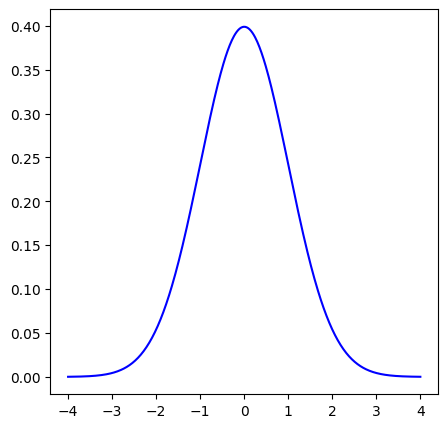

In [2]:
from scipy.stats import norm

x = np.linspace(-4, 4, 500)
pdf = norm.pdf(x)
plt.figure(figsize=(5, 5))
plt.plot(x, pdf, color='blue', label='Normal Distribution PDF')

In [3]:
Q1 = norm.ppf(0.25)
Q3 = norm.ppf(0.75)
print(Q1)
print(Q3)

-0.6744897501960817
0.6744897501960817


In [4]:
# Intervalo interquartílico (II)

II = Q3 - Q1
print(II)

1.3489795003921634


Os limites desse boxplot seriam

In [5]:
print(f"({Q1 - 1.5*II},{Q3 + 1.5*II})")

(-2.697959000784327,2.697959000784327)


Beleza, mas por quê?

A probablidade de observarmos valores dentro desse intervalo

$$P(-2.698\leq Z\leq2.698) = P(Z\leq2.698) - (Z\leq-2.698)$$

**CONSIDERANDO A DISTRIBUIÇÃO NORMAL** pode ser calculada no python com o seguinte comando (float é opcional)

In [6]:
prob = float(norm(0, 1).cdf(Q3 + 1.5*II) - norm(0, 1).cdf(Q1 - 1.5*II))
print(prob)

0.9930233967607198


Então 99.3023% das observações devem estar dentro desses limites, ou seja, é um evento muito raro observarmos qualquer coisa fora dos limites do boxplot.

A probabilidade de observarmos algo fora dos limites do boxplot é de

In [7]:
1-prob

0.006976603239280177

Ou seja, se tivermos 1000 observações, esperamos que apenas sete delas estejam fora desses limites. Um evento muito raro.

In [8]:
7/1000

0.007

Os mesmos passos podem ser seguidos para qualquer outros valores de média e variância da distribuição normal devido ao seguinte resultado. Se temos $Z \sim \mathrm{N}(0,1)$ e definimos $X = \mu + \sigma Z$, então $X \sim \mathrm{N}(\mu,\sigma^2)$. Daí podemos trocar aquela $Z$ nos calculos de antes por qualquer normal.

Text(0, 0.5, 'N$(4,1.1^2)$')

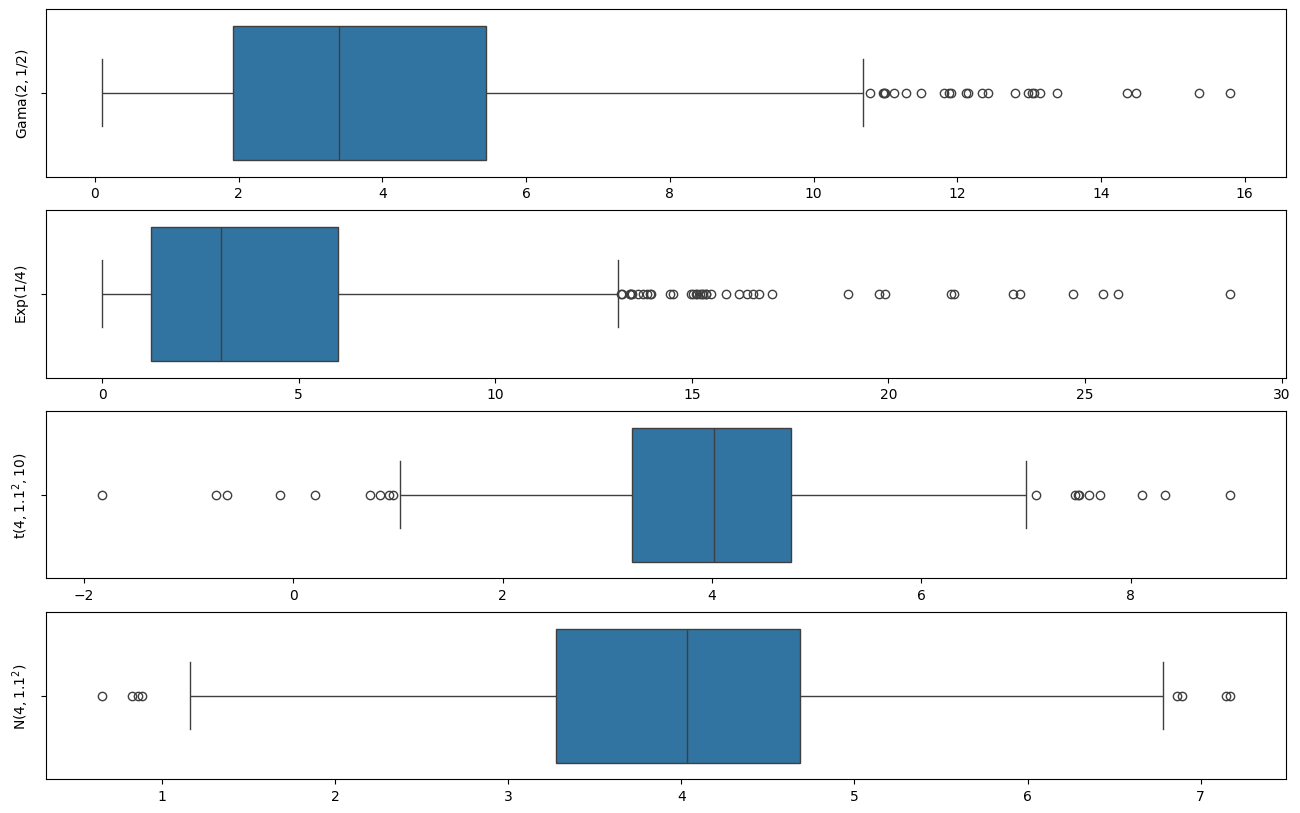

In [9]:
n = 1000

np.random.seed(6) # para reproduzir os dados gerados
X1 = np.random.gamma(shape=2, scale=2, size=n)
X2 = np.random.exponential(scale=4, size=n)
X3 = np.random.standard_t(10,size=n)
X3 = (X3*1.1)+4
X4 = np.random.normal(loc=4, scale = 1.1, size=n)

fig, axes = plt.subplots(4,1,figsize=(16, 10)) ## h, v

sns.boxplot(data=X1, orient="h",ax = axes[0])
axes[0].set_ylabel('Gama$(2,1/2)$')
sns.boxplot(data=X2, orient="h",ax = axes[1])
axes[1].set_ylabel('Exp$(1/4)$')
sns.boxplot(data=X3, orient="h",ax = axes[2])
axes[2].set_ylabel('t$(4,1.1^2,10)$')
sns.boxplot(data=X4, orient="h",ax = axes[3])
axes[3].set_ylabel('N$(4,1.1^2)$')

A justificativa para o valor 1.5 é essa, observar algo acima do limite máximo do boxplot ou abaixo do limite mínimo é muito raro. Vejam que é algo meio arbitrário e inclusive o python nos permite trocar esse valor.

Com o seaborn isso é feito pelo argumento `whis` (https://seaborn.pydata.org/generated/seaborn.boxplot.html)

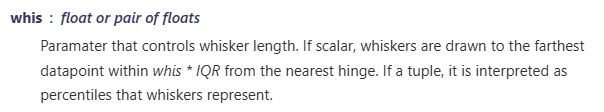

Text(0, 0.5, 'N$(4,1.1^2)$')

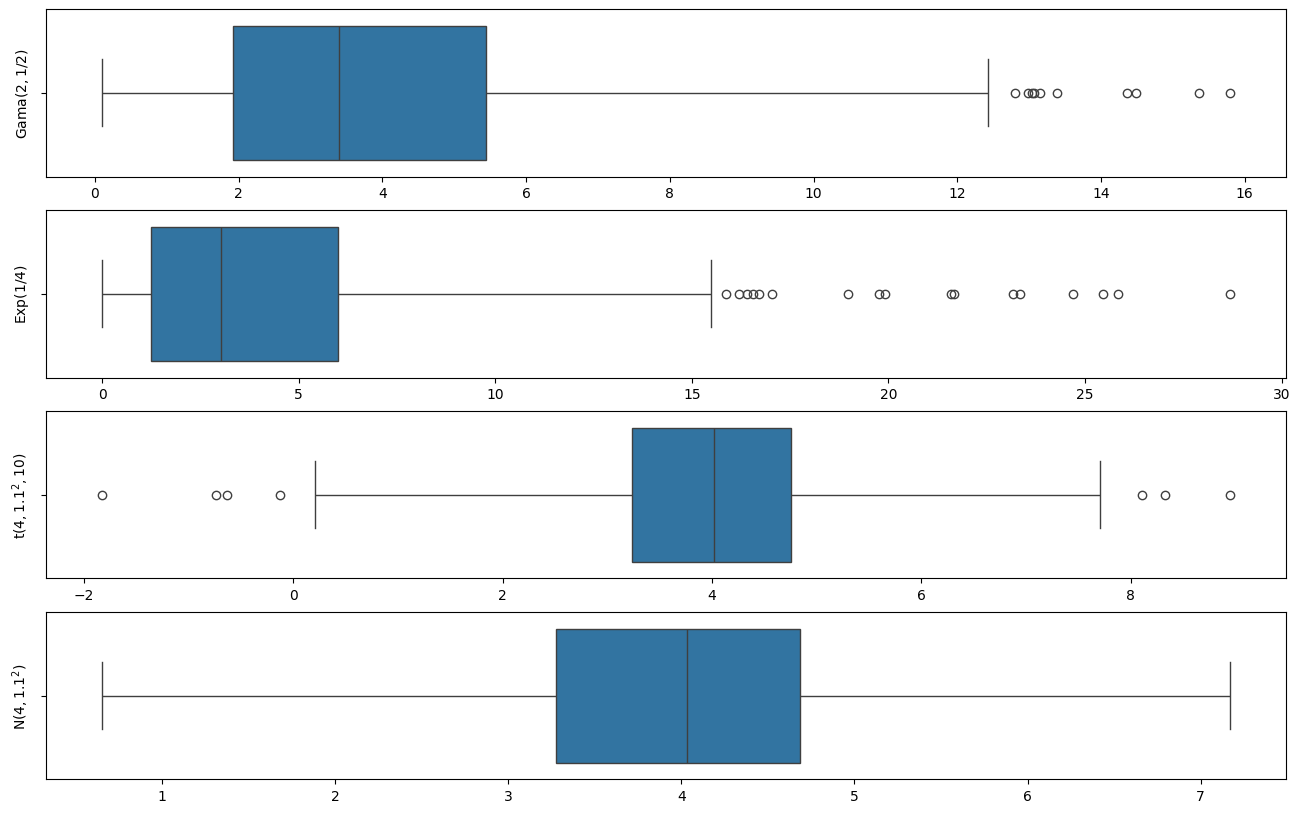

In [10]:
fig, axes = plt.subplots(4,1,figsize=(16, 10)) ## h, v

sns.boxplot(data=X1, orient="h",ax = axes[0], whis = 2.0)
axes[0].set_ylabel('Gama$(2,1/2)$')
sns.boxplot(data=X2, orient="h",ax = axes[1], whis = 2.0)
axes[1].set_ylabel('Exp$(1/4)$')
sns.boxplot(data=X3, orient="h",ax = axes[2], whis = 2.0)
axes[2].set_ylabel('t$(4,1.1^2,10)$')
sns.boxplot(data=X4, orient="h",ax = axes[3], whis = 2.0)
axes[3].set_ylabel('N$(4,1.1^2)$')

Aumentar esse valor de 1.5 para 2.0 muda a probabilidade de observarmos algo fora dos limites do boxplot para

In [11]:
1-float(norm(0, 1).cdf(Q3 + 2.0*II) - norm(0, 1).cdf(Q1 - 2.0*II))

0.0007450295031912191

esperamos observar 7 fora em 10 mil observações.

A detecção de outliers por meio do boxplot é útil para encontrarmos inconsistências no nosso banco de dados (altura de uma pessoa ser 1.71cm, peso negativo e etc.).

Detectadas essas inconsistências devemos tentar corrigí-las (a altura poderia ser 171cm, tentariamos coletar novamente o peso da pessoa).

Caso o outlier não represente uma inconsistência, ou seja, o comportamento dos dados é realmente esse, o outlier deve ser preservado e considerado em nossas análises posteriores.

# 2. Análise exploratoria do conjunto de dados Iris
A primeira coisa a se fazer é familiarizar-se com o conjunto de dados. O conjunto de dados Iris consiste de medidas retiradas de três espécies de plantas do gênero Iris, veja https://en.wikipedia.org/wiki/Iris_flower_data_set.

In [12]:
# Carrega o conjunto de dados
data = datasets.load_iris(as_frame = True)
df_iris = data.frame

display(df_iris.head(4))
display(df_iris.tail(4))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


traduzindo as variáveis

In [13]:
df_iris.columns = ["comp_sepala", "larg_sepala", "comp_petala", "larg_petala", "especie"]
display(df_iris.head(4))
display(df_iris.tail(4))

,comp_sepala,larg_sepala,comp_petala,larg_petala,especie
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0


,comp_sepala,larg_sepala,comp_petala,larg_petala,especie
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


Comecemos reconhecendo as variáveis qualitativas e quantitativas. Uma forma de fazer isso rapidamente é através da construção de histogramas com um alto número de divisões. Para fazermos histogramas com o seaborn precisamos transformar o conjunto de dados usando o método melt.

In [14]:
# Transforma o dataframe para um formato longo
df_melted = pd.melt(df_iris, var_name='variable', value_name='value')
display( df_melted.head(4) )
display( df_melted.tail(4) )

,variable,value
0,comp_sepala,5.1
1,comp_sepala,4.9
2,comp_sepala,4.7
3,comp_sepala,4.6


,variable,value
746,especie,2.0
747,especie,2.0
748,especie,2.0
749,especie,2.0


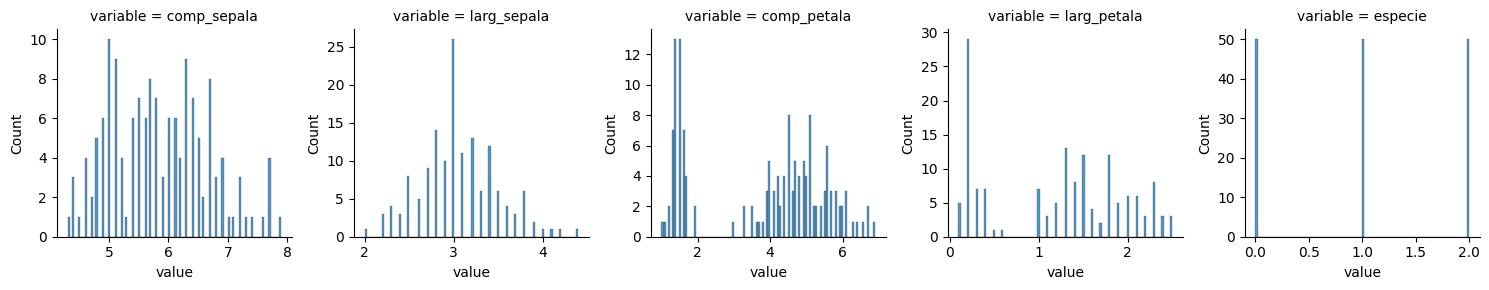

In [15]:
g = sns.FacetGrid(df_melted, col="variable", col_wrap = 5, sharex=False, sharey=False)
g.map_dataframe(sns.histplot, x = "value", bins = 100)

O "truque" não funcionou muito bem. Variáveis quantitativas contínuas devem aparecer como barras bem próximas umas as outras, enquanto variáveis quantitativas discretas ou qualitativas aparecem como barras separadas.

Utilizamos então nosso conhecimento sobre os dados. Esse comportamento se deve a forma de coleta. As variáveis `comp_sepala`, `larg_sepala`, `comp_petala` e `larg_petala` são quantitativas contínuas. `comp_sepala` de 5.10918238123... ou 5.10012903128... são completamente plausíveis de serem observados, porém, na hora do registro, foi escrito apenas 5.1, colocando todos esses valores próximos de 5.1 na mesma categoria.

A variável `especie` mostra o comportamento típico de uma variável quantitativa discreta ou qualitativa. Um dado quantitativo discreto, usualmente, se refere a uma contagem de algo, ou seja, uma quantidade realmente palpável na vida real. Do nosso conhecimento sobre os dados, sabemos que ela é qualitativa, afinal de contas a variável apenas indica qual a especie da planta. Agora, é qualitativa nominal ou ordinal?

Quando podemos atribuir alguma ordem as categorias de uma variável qualitativa, como por exemplo, o nível de satisfação do cliente, o grau de escolaridade, passamos a ter variáveis qualitativas ordinais. Veja que não é possível fazer isso para a variável `especie`.



In [16]:
summary = df_melted.groupby('variable').describe()

print(summary)

             value                                              
             count      mean       std  min  25%   50%  75%  max
variable                                                        
comp_petala  150.0  3.758000  1.765298  1.0  1.6  4.35  5.1  6.9
comp_sepala  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
especie      150.0  1.000000  0.819232  0.0  0.0  1.00  2.0  2.0
larg_petala  150.0  1.199333  0.762238  0.1  0.3  1.30  1.8  2.5
larg_sepala  150.0  3.057333  0.435866  2.0  2.8  3.00  3.3  4.4


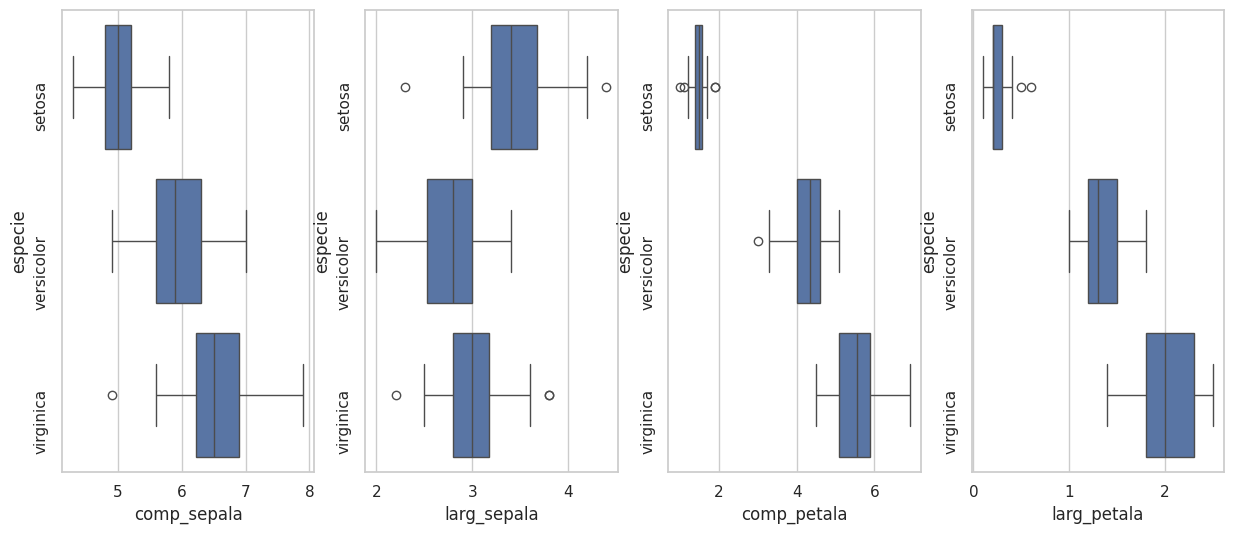

In [45]:
vars = df_iris.columns[:-1]
fig, ax = plt.subplots(nrows = 1, ncols = len(vars), figsize = (15,6))

for i in range(len(vars)):
  ax[i].tick_params(axis='y', rotation=90)
  sns.boxplot(x = vars[i], y = 'especie', data = df_iris, ax = ax[i])


## Relação entre variáveis
Geralmente estamos interessados em como duas ou mais variáveis estão relacionadas. Infelizmente não podemos enxergar diretamente em mais de três dimensões.

In [18]:
data.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [19]:
# Atualiza para os nomes das espécies
df_iris["especie"] = data.target_names[df_iris["especie"]]

display(df_iris.head(2))
display(df_iris.tail(2))

,comp_sepala,larg_sepala,comp_petala,larg_petala,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa


,comp_sepala,larg_sepala,comp_petala,larg_petala,especie
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


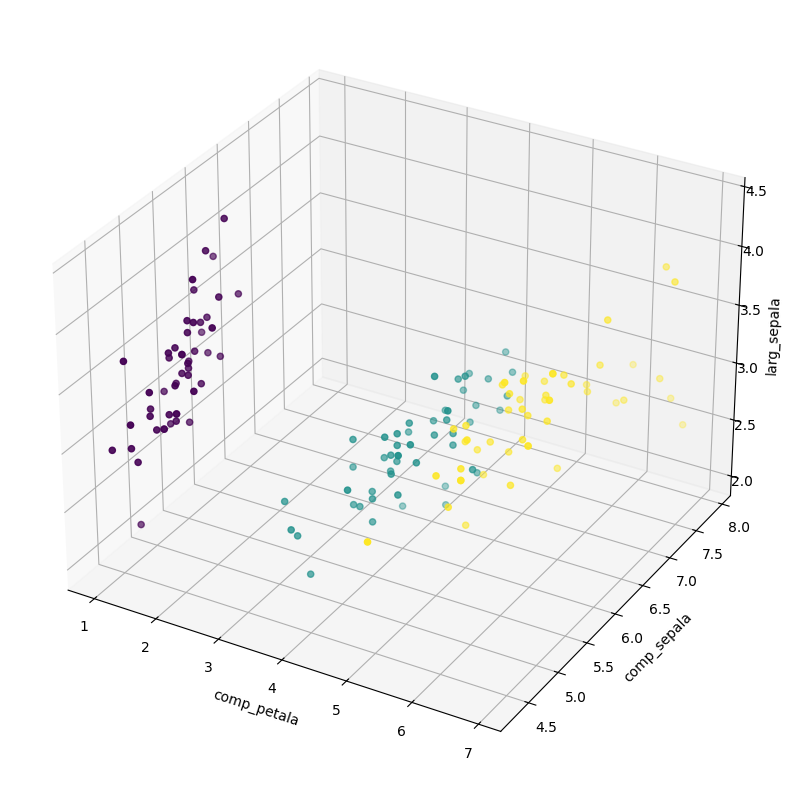

In [20]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d', xlabel = "comp_petala", ylabel ="comp_sepala")
ax.set_zlabel("larg_sepala", labelpad=-5)
ax.tick_params(axis="z", pad=-3)
ax.scatter(df_iris["comp_petala"], df_iris["comp_sepala"], df_iris["larg_sepala"], c = data.target)
plt.show()

In [21]:
def pair_plot(df, variables, hue = None, regplot = True):
    def corrfunc(x, y, hue, **kws):
        if(hue is not None):
            # Número de classes
            num_classes = len(hue.unique())

            color_palette = sns.color_palette().as_hex()

            # Para cada classe, calcula as correlações
            corrs = []
            for class_value in hue.unique():
                corr = np.corrcoef(x[hue == class_value], y[hue == class_value])[0, 1]
                corrs.append(corr)
            corr_xy = np.corrcoef(x, y)[0, 1]

            ax = plt.gca()

            # Divide o espaço do grid no número de classes
            y_positions = np.linspace(0, 1, num_classes + 2)[1:-1]

            for j in range(len(corrs)):
                ax.annotate("{:.2f}".format(corrs[j], hue.unique()[j]), xy=(0.3, y_positions[j]), xycoords=ax.transAxes,
                            ha='center', va='center', fontsize=18, color=color_palette[j%10])

            # Adiciona a correlação geral desconsiderando as classes (em preto)
            ax.annotate("({:.2f})".format(corr_xy), xy=(0.75, 0.5), xycoords=ax.transAxes,
                        ha='center', va='center', fontsize=18, color="black")
        else:
            ax = plt.gca()
            corr_xy = np.corrcoef(x, y)[0, 1]
            # Adiciona a correlação geral desconsiderando as classes (em preto)
            ax.annotate("{:.2f}".format(corr_xy), xy=(0.5, 0.5), xycoords=ax.transAxes,
                        ha='center', va='center', fontsize=18, color="black")

    # Custom regplot function to color regression lines
    def regplot_hue(x, y, hue, **kwargs):
        ax = plt.gca()

        for i, class_value in enumerate(np.unique(hue)):
            xp = x[hue == class_value]
            yp = y[hue == class_value]
            sns.regplot(x = xp, y = yp, scatter=False,
                        line_kws={"color": sns.color_palette()[i%10]}, ax = ax)

    if(hue is not None):
        df = df.loc[:, variables + [hue] ]
        df[hue] = df[hue].astype(str)
    else:
        df = df.loc[:, variables]

    if(hue is None):
        g = sns.PairGrid(df, diag_sharey = False)
        g.map_lower(sns.scatterplot, data = df, alpha=0.7)
        g.map_lower(sns.regplot, scatter=False, color = "black")
    else:
        g = sns.PairGrid(df, hue = hue, diag_sharey = False)
        g.map_lower(sns.scatterplot, hue = hue, data = df, alpha=0.7)
        g.map_lower(regplot_hue)

    g.map_diag(sns.histplot, kde=True)
    g.map_upper(corrfunc)

    if(hue is not None):
        # Adiciona a legenda ao grid manualmente
        handles = [plt.Line2D([0], [0], marker='o', color='w',
                               markerfacecolor=sns.color_palette()[i%10], markersize=10,
                               label=species)
                   for i, species in enumerate(df[hue].unique())]

        plt.legend(handles=handles, title=hue, loc="upper left", bbox_to_anchor=(1, 1))



    plt.show()

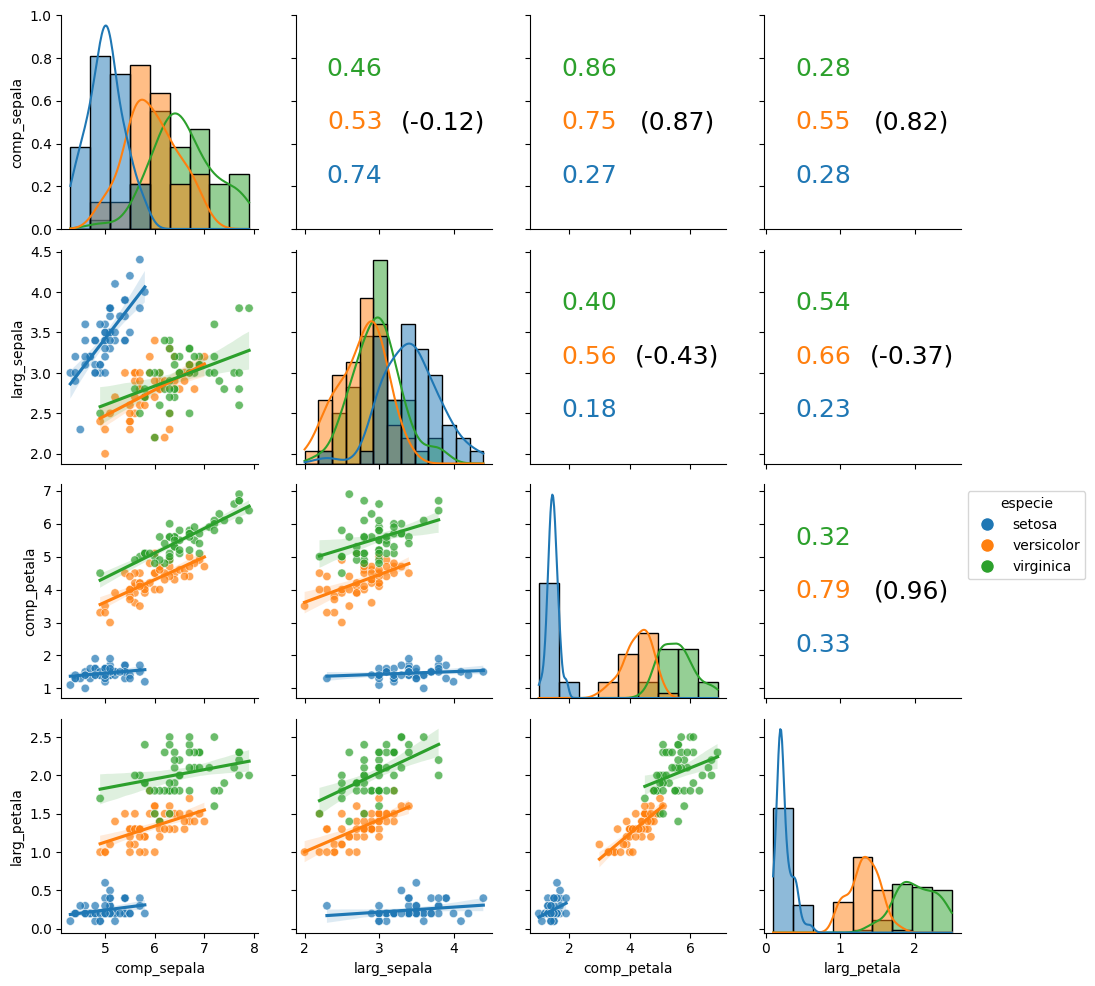

In [22]:
pair_plot(df_iris, ["comp_sepala", "larg_sepala", "comp_petala", "larg_petala"], hue = "especie")

Veja, por exemplo, na interação entre `larg_sepala` e `comp_petala`. As correlações individuais de cada grupo indicam uma correlação positiva entre as variáveis, ou seja, o aumento de uma leva ao aumento da outra. Entretanto, veja que a correlação geral (desconsiderando os grupos) é negativa! Sendo assim, se não conhecemos qual o grupo de cada flor, então passamos a dizer que `larg_sepala` de fato diminui com o aumento de `comp_petala`. Parece um resultado contraditório, não?

De fato, esse fenômeno é conhecido como Paradoxo de Simpson, uma vez que parece não fazer sentido! De fato, esse paradoxo demonstra o quão complexas podem ser as relações entre duas variáveis, de modo que a simples adição de uma nova variável (o grupo da flor, neste caso) pode mudar completamente a interpretação dos resultados obtidos.

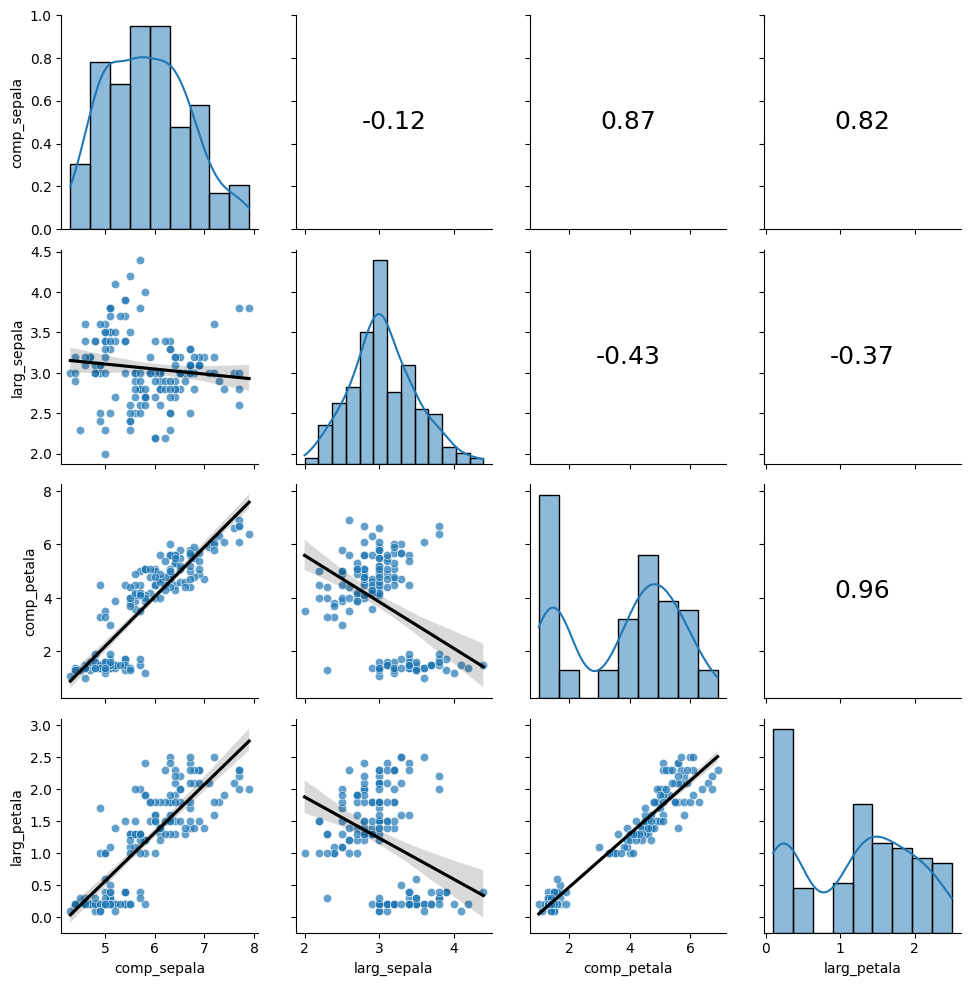

In [23]:
pair_plot(df_iris, ["comp_sepala", "larg_sepala", "comp_petala", "larg_petala"])

Outra coisa importante, não confundam correlação e causalidade. Duas variáveis estarem correlacionadas não quer dizer que uma cause a outra ou a outra cause uma. No nosso conjunto de dados, vimos várias correlações entre variáveis, mas não é porque existe uma correlação entre `larg_sepala` e `comp_petala` que um aumento em `larg_sepala` de uma determinada espécie cause um aumento em `comp_petala` dessa mesma espécie. A meu ver, `larg_sepala` e `comp_petala` possuem apenas uma associação, enquanto a espécie da planta possui uma relação de causalidade com essas duas variáveis

![image.png](https://www.tylervigen.com/spurious/correlation/scatterplot/5230_popularity-of-the-first-name-dexter_correlates-with_google-searches-for-bing_scatterplot.png)


Vejam mais exemplos em https://www.tylervigen.com/spurious-correlations

# 3. Análise Exploratória dos dados do Spotify

In [24]:
df = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/main/Music_DB.csv', decimal=',')
display(df.head(4))
display(df.tail(4))

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Tipo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.964,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.269,0,audio_features,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.955,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.550,1,audio_features,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.939,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.661,1,audio_features,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.969,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.538,1,audio_features,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer


,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Tipo,Music_id,Playlist_name,Album_name,Artista,Music_name
7698,0.941,0.0852,124.977,0.0337,0.000026,0.000025,4,0.525,9,177347,0.665350,0.541,0,audio_features,1VKTwfRivDO6neMF6mm9QZ,Nervous,Battle Beast,Battle Beast,Out on the Streets
7699,0.933,0.1740,82.807,0.0774,0.000904,0.000008,4,0.445,4,279587,0.542875,0.517,0,audio_features,3bGMBNy2fhhKYF1haK6pYg,Nervous,Bringer of Pain,Battle Beast,Beyond the Burning Skies
7700,0.886,0.1120,110.021,0.0353,0.000091,0.000431,4,0.506,2,328787,0.630376,0.200,0,audio_features,6NTEk76W6mraayMZV5zhhR,Nervous,Battle Beast,Battle Beast,Into the Heart of Danger
7701,0.966,0.1300,160.018,0.0656,0.000009,0.238000,4,0.445,4,225133,0.657885,0.486,0,audio_features,0PUlrv1mHz4DOTqTEOe8kB,Nervous,Battle Beast,Battle Beast,Out of Control


In [25]:
display(df['Tipo'].unique()) # joga fora

df = df.drop('Tipo', axis = 1)
df

array(['audio_features'], dtype=object)

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.964,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.269,0,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.955,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.550,1,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.939,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.661,1,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.969,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.538,1,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer
4,0.970,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.427,0,5egqKwgK5r5rvGD1LrtR7J,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Points of Authority
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7697,0.920,0.0562,100.007,0.0369,0.002120,0.000008,4,0.544,4,272013,0.448745,0.683,0,0tJipFCATY8M2WWXXNyJ9p,Nervous,Unholy Savior,Battle Beast,Touch In The Night
7698,0.941,0.0852,124.977,0.0337,0.000026,0.000025,4,0.525,9,177347,0.665350,0.541,0,1VKTwfRivDO6neMF6mm9QZ,Nervous,Battle Beast,Battle Beast,Out on the Streets
7699,0.933,0.1740,82.807,0.0774,0.000904,0.000008,4,0.445,4,279587,0.542875,0.517,0,3bGMBNy2fhhKYF1haK6pYg,Nervous,Bringer of Pain,Battle Beast,Beyond the Burning Skies
7700,0.886,0.1120,110.021,0.0353,0.000091,0.000431,4,0.506,2,328787,0.630376,0.200,0,6NTEk76W6mraayMZV5zhhR,Nervous,Battle Beast,Battle Beast,Into the Heart of Danger


In [26]:
display(len(df['Music_id'].unique()))
df.shape

6722

(7702, 18)

In [27]:
my_list = df['Music_id'].tolist()
non_unique_items = [item for item in set(my_list) if my_list.count(item) > 1]
print(non_unique_items)
n = len(non_unique_items)
lis = []

for i in range(len(non_unique_items)):
  lis.append(np.where(df["Music_id"] == non_unique_items[i])[0].tolist())

def flatten(xss):
    return [x for xs in xss for x in xs]

lis = flatten(lis)

print(lis)

df.loc[lis]

['2qHGPanT2ux9hwZDbmPr8t', '0oufSLnKQDoBFX5mgkDCgR', '4d4OJTq2Yl7TyiuGMLxa1h', '0OAJaP0HI69nJPpHMPRbSu', '4poybupy26pTWPr9zY1i7h', '7pDD127Pc7US1ZG0sJy3e0', '75pcpojFTJnyfeGw0YrEQ9', '0sk2c1F1WqhnBDFlxefiQM', '4esOae7i4rqTbAu9o5Pxco', '4zvqMZ6g4wKZaPpOQvoBpP', '0Sn8lWeOkc5crNhOus3hw9', '0Ycl08JD5MBn28OPznygwz', '6TEiFwaiHERpdfG6WnGed1', '4VrWlk8IQxevMvERoX08iC', '14JtWuoCt1JnztTsSx5xC8', '1Ff9bSqXJkerZyKfBtLUNw', '4Of7rzpRpV1mWRbhp5rAqG', '3bkDRZy33aVQHK8PZsIPLH', '2TIlqbIneP0ZY1O0EzYLlc', '0sf12qNH5qcw8qpgymFOqD', '5d41vXH0zvpwUrHrmqKqDc', '2a2oviLv9lvwFJr3TZ8rOD', '5k38wzpLb15YgncyWdTZE4', '7w87IxuO7BDcJ3YUqCyMTT', '2K4qtTAE8fjFaIUBFTuj1a', '666R681YMygTRKZSYxy15D', '3bBGo3Le7RDVWYqA7xkwgy', '0kQ5pSKTrXn3ABSJEnB9ls', '10Odr9VhsEYfpd3hjoNyl3', '6WkXlCEHH8wkQ5xGytORl6', '5p3moUVU9JBeuj67GmZjSZ', '3MTUSGqYlX2A9TNByj0abb', '1FDBXMv6YUzZYCcGlzqovz', '25ScmRjdUWeTd6lfGpvvOn', '5ca7B7Qi2gpzPELK9lBab0', '3FGyavyOBVi9W1tk0yGeuX', '1Vv5St0rzB3054EvkADdQi', '3Fux0MjrZert93z8sT3zNp', '0BYHrCCKTQ

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Music_id,Playlist_name,Album_name,Artista,Music_name
5490,0.00272,0.116,68.220,0.0410,0.987000,0.879000,4,0.201,10,152000,0.017440,0.0992,1,2qHGPanT2ux9hwZDbmPr8t,Relaxed,Éjszakai,Vas Bela,Éjszakai
6505,0.00272,0.116,68.220,0.0410,0.987000,0.879000,4,0.201,10,152000,0.017440,0.0992,1,2qHGPanT2ux9hwZDbmPr8t,Sleepy,Éjszakai,Vas Bela,Éjszakai
7245,0.00272,0.116,68.220,0.0410,0.987000,0.879000,4,0.201,10,152000,0.017440,0.0992,1,2qHGPanT2ux9hwZDbmPr8t,Sleepy,NaN,NaN,NaN
1128,0.39600,0.120,92.006,0.1590,0.227000,0.000075,4,0.764,8,158421,0.372992,0.4750,1,0oufSLnKQDoBFX5mgkDCgR,Boring,Lost,Brent Faiyaz,Trust
5121,0.39600,0.120,92.006,0.1590,0.227000,0.000075,4,0.764,8,158421,0.372992,0.4750,1,0oufSLnKQDoBFX5mgkDCgR,Pleased,Lost,Brent Faiyaz,Trust
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3829,0.11600,0.109,137.815,0.0706,0.936000,0.934000,4,0.440,0,133590,0.106807,0.2440,1,6jOIw4rA5ykDm1lW8f6PG9,Peaceful,Dissolution,Auguste Braun,Dissolution
3565,0.98600,0.350,105.158,0.1680,0.000003,0.394000,4,0.314,7,204760,0.720361,0.0975,1,7mTUApLiOIcFfwzXiyTzw4,Nervous,Agony,Nervosa,Hostages
7628,0.98600,0.350,105.158,0.1680,0.000003,0.394000,4,0.314,7,204760,0.720361,0.0975,1,7mTUApLiOIcFfwzXiyTzw4,Nervous,Agony,Nervosa,Hostages
3850,0.03720,0.124,88.666,0.0324,0.989000,0.945000,4,0.199,8,278710,0.031250,0.1170,0,5hSbyGmtlbby8POW2w9yGp,Peaceful,Early Bird,Adam By Nature,Early Bird


In [28]:
display(len(df['Music_name'].unique()))
df.shape

4747

(7702, 18)

In [29]:
my_list2 = df['Music_name'].tolist()
non_unique_items2 = [item for item in set(my_list2) if my_list2.count(item) > 1]
print(non_unique_items2)
lis2 = []

for i in range(len(non_unique_items2)):
  lis2.append(np.where(df["Music_name"] == non_unique_items2[i])[0].tolist())

lis2 = flatten(lis2)

print(lis2)

df.loc[lis2]


['cognizant', 'No More', 'Nocturno', 'Him & I (with Halsey)', 'Getting Dark', 'The Devil in I', 'Bikinisinde Astronomi (Bonus Trek)', 'Invisible Oppression', 'Isla De Flores', 'What You Know', 'Put A Little Love On Me', 'Dream #5 [Drifting Apart]', 'Cozy Little Christmas', 'Alien Artifact', 'When We Were Young', 'More Than Anything', "Don't Go Breaking My Heart", nan, 'Half A Man', 'The Night We Met', 'Semblance of Reality', 'Leviathan', 'Mandala', 'Glorious', 'Perspectives', "Bartram's Garden", 'Symbols', 'Wren', 'Call to Rest', 'Señorita', 'Presto arriverà il sole', 'The Brave and the Bold', 'The Mystery', 'Distance', 'Mantra', 'Worst of You', 'Brick Beat', 'Say Something', 'If You Need To, Keep Time On Me', 'Lionheart', 'Lie', 'Girlfriend', 'Lhotse', 'Gone', 'Alright', 'Relief', 'Sprites Of The Moor', "I'm Yours", 'Monster', 'Return Of Captain Chaos', 'Happiness', 'Chandelier', 'Saviour of Nothing', 'Machine', 'Sun', 'Never Wrong', 'Just Give Me a Reason', 'The Band of the Hawk', 'A

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Music_id,Playlist_name,Album_name,Artista,Music_name
3792,0.018,0.1190,68.249,0.0357,0.977000,0.863000,4,0.120,2,191000,0.028566,0.0924,0,5CC8QT7TuttcXXSlj5cx2T,Peaceful,cognizant,Lori Dulac,cognizant
6557,0.018,0.1190,68.249,0.0357,0.977000,0.863000,4,0.120,2,191000,0.028566,0.0924,0,5CC8QT7TuttcXXSlj5cx2T,Sleepy,cognizant,Lori Dulac,cognizant
40,0.916,0.1560,197.817,0.0581,0.002610,0.000000,4,0.271,6,225493,0.696546,0.2860,0,1bPRhOz3nOfEIoLjB1YYT3,Angry,Life Starts Now,Three Days Grace,No More
506,0.988,0.2220,101.280,0.1210,0.000285,0.000000,3,0.530,7,232640,0.758054,0.5210,1,2xECSFHPgCyElhTVRaHVYP,Angry,Evolution (Deluxe Edition),Disturbed,No More
3314,0.571,0.0812,130.983,0.0526,0.072000,0.007760,4,0.796,1,183292,0.441621,0.3960,0,6oA7NzN7FgmXv7l7Y638HL,Happy,No More,Olivera,No More
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7407,0.921,0.1010,118.069,0.0373,0.000128,0.766000,4,0.590,7,132092,0.389718,0.9690,1,50oLd0iLLvfuqozyI58lrT,Nervous,Somewhere Over Yellow,Vannessa Hewlett,Somewhere Over Yellow
4466,0.430,0.1170,136.824,0.0282,0.608000,0.000003,4,0.578,10,243187,0.478851,0.1560,1,2deFH5zveEBEUuURpqTN3C,Peaceful,YOU,James Arthur,Quite Miss Home
6003,0.430,0.1170,136.824,0.0282,0.608000,0.000003,4,0.578,10,243187,0.478851,0.1560,1,2deFH5zveEBEUuURpqTN3C,Sad,YOU,James Arthur,Quite Miss Home
1088,0.710,0.0956,127.975,0.0292,0.145000,0.115000,4,0.733,5,239600,0.509976,0.9650,0,7w87IxuO7BDcJ3YUqCyMTT,Boring,Torches,Foster The People,Pumped Up Kicks


In [30]:
df = df.drop_duplicates()
df

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.96400,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.26900,0,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.95500,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.55000,1,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.93900,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.66100,1,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.96900,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.53800,1,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer
4,0.97000,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.42700,0,5egqKwgK5r5rvGD1LrtR7J,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Points of Authority
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7380,0.14300,0.6180,113.910,0.3680,0.179000,0.987000,5,0.162,1,149190,0.133706,0.00001,1,0xRCupcaql1nxAlUaj1SiL,Sleepy,NaN,NaN,NaN
7381,0.67700,0.9710,81.670,0.1030,0.274000,0.973000,5,0.207,1,265352,0.035543,0.01980,1,3gmfFneY6uzrz6MON0A9eI,Sleepy,NaN,NaN,NaN
7382,0.37700,0.4110,62.014,0.0584,0.164000,0.998000,4,0.206,7,104908,0.166456,0.00001,1,2U2i6tqHzKA6kUkYpArz76,Sleepy,NaN,NaN,NaN
7383,0.00354,0.8700,91.579,0.4700,0.565000,0.975000,3,0.124,7,151067,0.155328,0.00001,1,6RfkQdyd9B1Q8SFNT6Wvwn,Sleepy,NaN,NaN,NaN


In [31]:
print("Colunas:\n{}".format(df.columns.to_list()))

Colunas:
['Energia', 'Ao_vivo', 'Tempo', 'Falado', 'Orgânico', 'Instrumental', 'Compasso', 'Dançabilidade', 'Tom', 'Duração', 'Força', 'Positividade', 'Modo', 'Music_id', 'Playlist_name', 'Album_name', 'Artista', 'Music_name']


In [32]:
from sklearn.preprocessing import LabelEncoder

# transforma nomes em numeros
def encoder(df, variaveis):
  le = LabelEncoder()
  nome_coluna_encoded = []
  for i in range(len(variaveis)):
    le.fit(df[variaveis[i]])
    dado = (f'{variaveis[i]}_encoded',le.transform(df[variaveis[i]]))
    nome_coluna_encoded.append(dado)
  for col_name, values in nome_coluna_encoded:
    df = df.assign(**{col_name: values})
  return df

variaveis = ["Music_id", "Playlist_name", "Album_name", "Artista", "Music_name"]
df_numeric = encoder(df, variaveis)
df_numeric = df_numeric.drop(variaveis, axis = 1)

display(df_numeric)

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Music_id_encoded,Playlist_name_encoded,Album_name_encoded,Artista_encoded,Music_name_encoded
0,0.96400,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.26900,0,565,0,2627,376,3933
1,0.95500,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.55000,1,2533,0,853,376,1894
2,0.93900,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.66100,1,1294,0,1589,1602,2956
3,0.96900,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.53800,1,2818,0,1589,1602,2868
4,0.97000,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.42700,0,4878,0,1589,1602,3056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7380,0.14300,0.6180,113.910,0.3680,0.179000,0.987000,5,0.162,1,149190,0.133706,0.00001,1,825,11,4227,3111,4746
7381,0.67700,0.9710,81.670,0.1030,0.274000,0.973000,5,0.207,1,265352,0.035543,0.01980,1,3159,11,4227,3111,4746
7382,0.37700,0.4110,62.014,0.0584,0.164000,0.998000,4,0.206,7,104908,0.166456,0.00001,1,2133,11,4227,3111,4746
7383,0.00354,0.8700,91.579,0.4700,0.565000,0.975000,3,0.124,7,151067,0.155328,0.00001,1,5549,11,4227,3111,4746


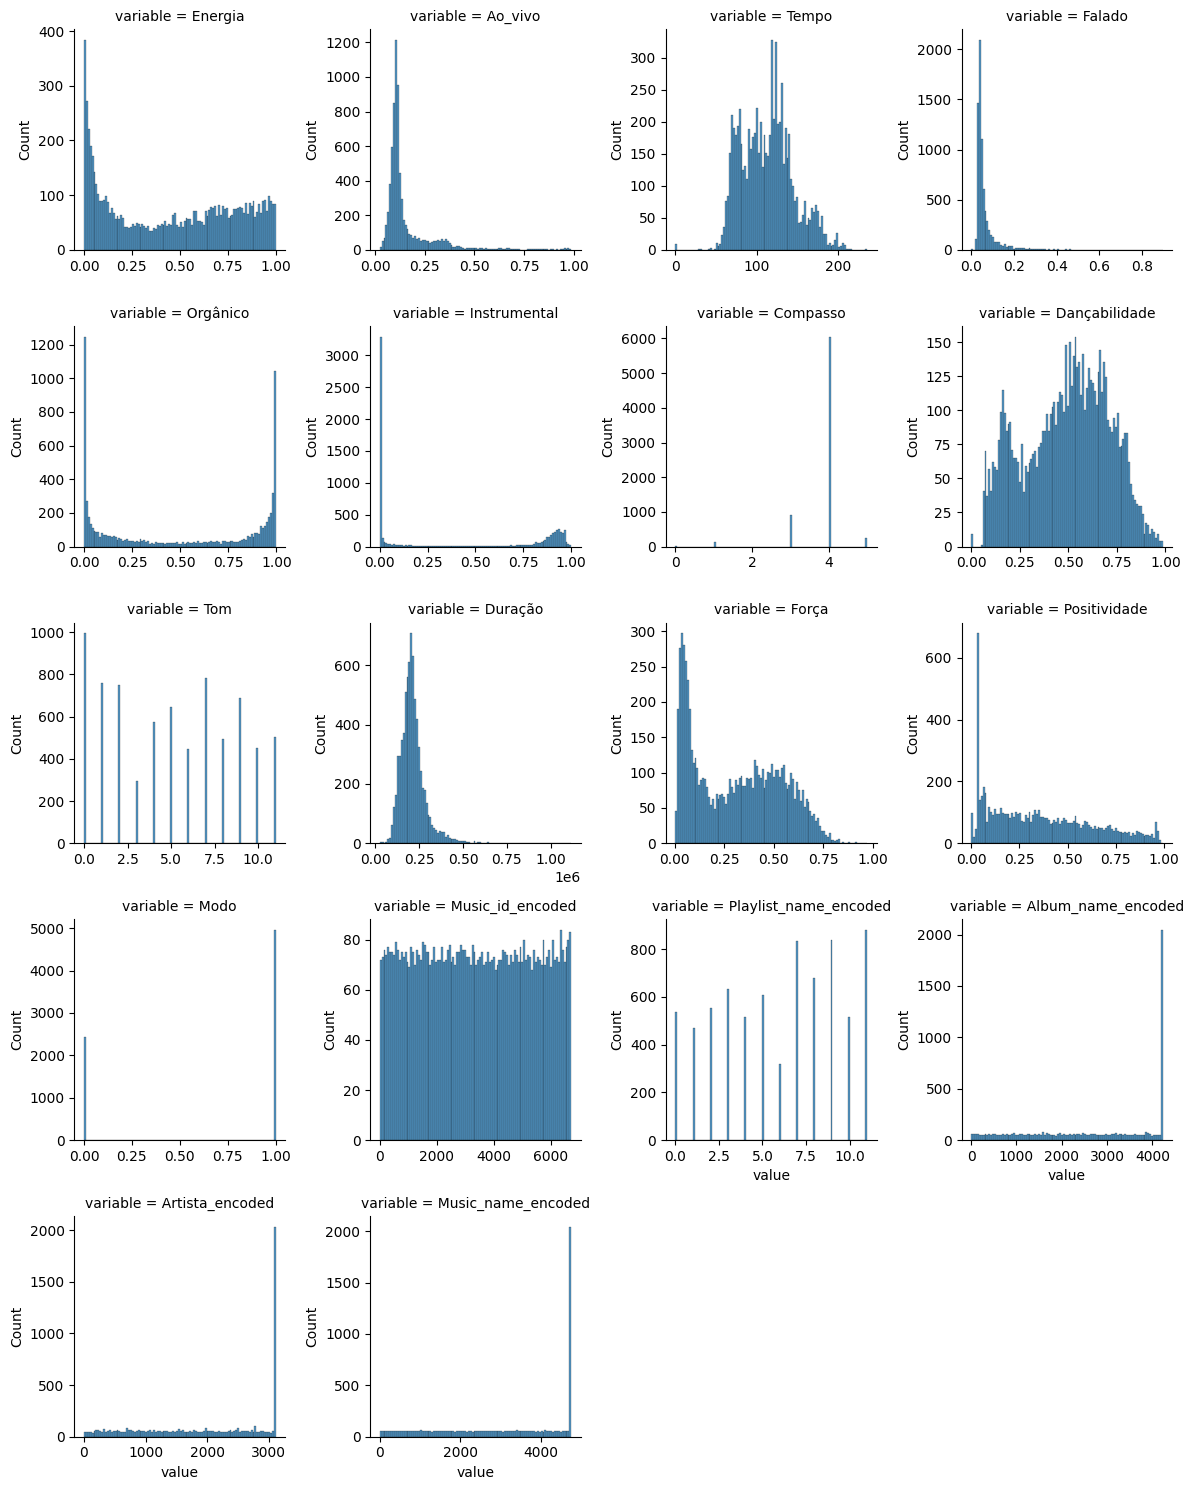

In [33]:
df_numeric_melted = pd.melt(df_numeric, var_name='variable', value_name='value')
g = sns.FacetGrid(df_numeric_melted, col="variable", col_wrap = 4, sharex=False, sharey=False)
g.map_dataframe(sns.histplot, x = "value", bins = 100)

In [34]:
df.isna().sum().tolist() # as tres ultimas variaveis apresentam valores faltantes

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1992, 1992, 1992]

In [35]:
def bar_plot(df, variable_name, ax = None):
    # Tabela de frequências absolutas
    tab = pd.crosstab(index = df[variable_name], columns = 'frequência')
    tab_normalize = pd.crosstab(index = df[variable_name], columns = 'frequência', normalize='columns')

    if(ax is None):
        fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,6))

    # Supondo que 'tab' seja uma tabela ou DataFrame que já foi definido
    tab_normalize.plot.bar(
        color='skyblue',
        legend=False,
        ax = ax
    )
    title = "Gráfico de barras - {}".format(variable_name)
    ax.set_title(title, fontsize=16)
    ax.set_xticks(ax.get_xticks())
    ax.tick_params(axis='x', rotation=0, labelsize = 12)

    # Faz o gráfico de barras por proporções, mas exibe as contagem em cima de cada barra
    for container in ax.containers:
        for rect in container.get_children():
            height = rect.get_height()
            ax.text(rect.get_x() + rect.get_width() / 2.0, height, int(height * len(df[variable_name])), ha='center', va='bottom')

    ax.set_ylabel('Frequência', fontsize=12)
    ax.set_xlabel('Categorias', fontsize=12)



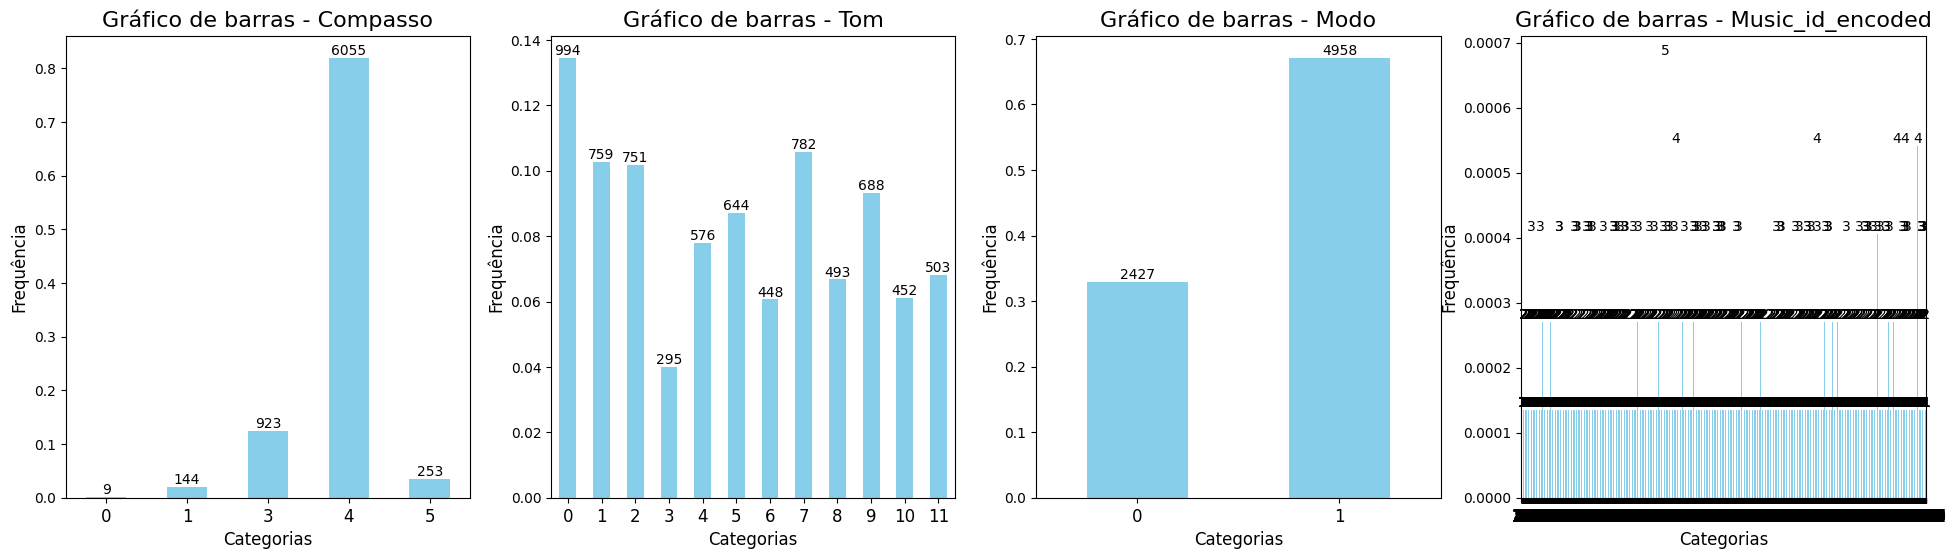

In [36]:
fig, ax = plt.subplots(nrows = 1, ncols = 4, figsize = (24, 6))

bar_plot(df_numeric, "Compasso", ax = ax[0])
bar_plot(df_numeric, "Tom", ax = ax[1])
bar_plot(df_numeric, "Modo", ax = ax[2])
bar_plot(df_numeric, "Music_id_encoded", ax = ax[3])

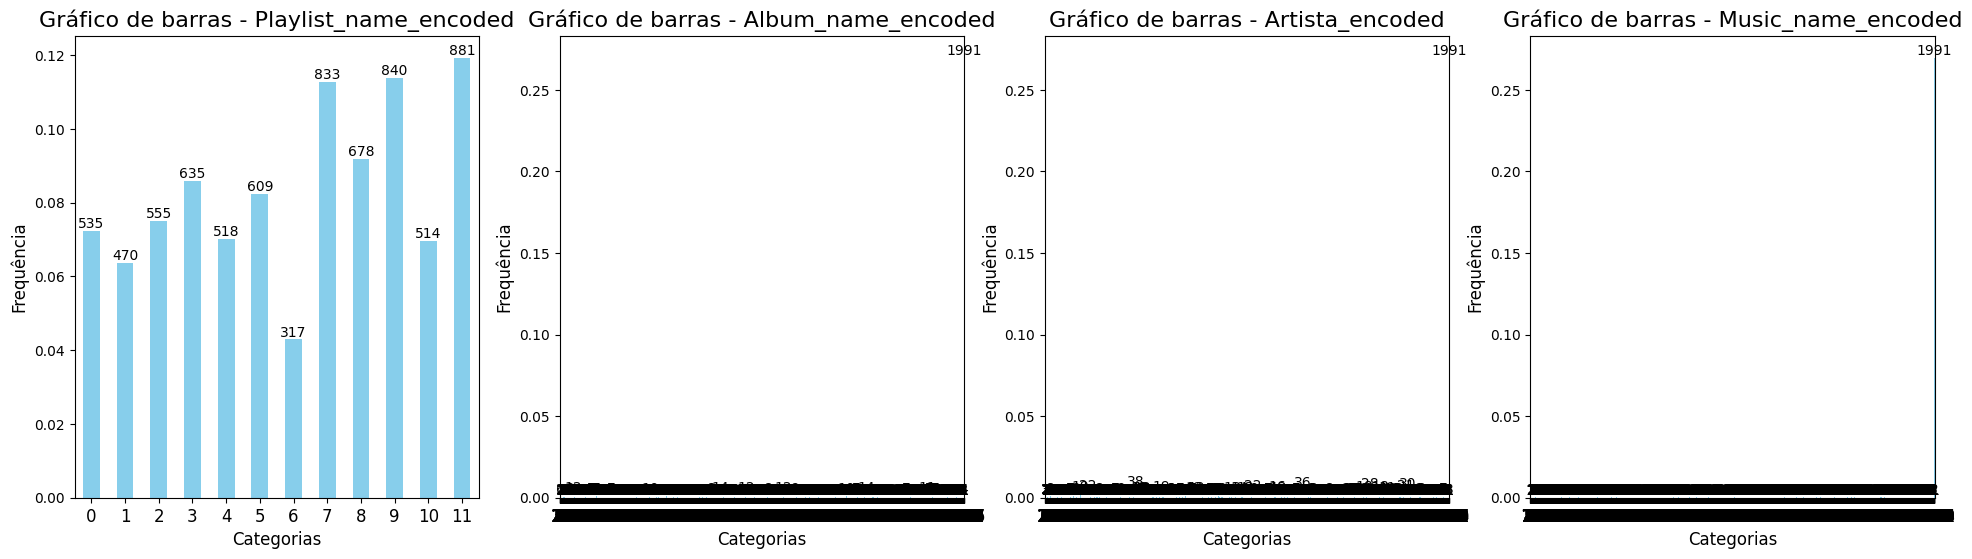

In [37]:
fig, ax = plt.subplots(nrows = 1, ncols = 4, figsize = (24, 6))

bar_plot(df_numeric, "Playlist_name_encoded", ax = ax[0])
bar_plot(df_numeric, "Album_name_encoded", ax = ax[1])
bar_plot(df_numeric, "Artista_encoded", ax = ax[2])
bar_plot(df_numeric, "Music_name_encoded", ax = ax[3])

In [38]:
def sector_plot(df, variable_name, ax = None):
    # Configuração estética do Seaborn
    sns.set(style="whitegrid")
    tab = pd.crosstab(index = df[variable_name], columns = 'frequência')
    tab_series = tab['frequência']

    # Cria o gráfico de donut
    # plt.figure(figsize=(15, 7), dpi=80)
    if(ax is None):
        fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12,6))

    # Cria o gráfico de donut
    tab_series.plot.pie(
        autopct = lambda pct: f'{pct:.0f}%',  # Adiciona os percentuais
        startangle = 90,                      # Inicia o gráfico a partir de 90 graus
        colors = sns.color_palette("pastel"), # Utiliza uma paleta de cores do Seaborn
        textprops = {'fontsize': 10},         # Ajusta o tamanho da fonte dos textos
        wedgeprops = {'width': 0.4},          # Ajusta a largura das fatias para criar o efeito donut
        pctdistance = 0.85,                   # Ajusta a distância dos percentuais
        ax = ax
    )

    # Adiciona um círculo branco no centro para criar o efeito donut
    centre_circle = plt.Circle((0, 0), 0.60, fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(centre_circle)

    title = "Gráfico de setores - {}".format(variable_name)
    ax.set_title(title)

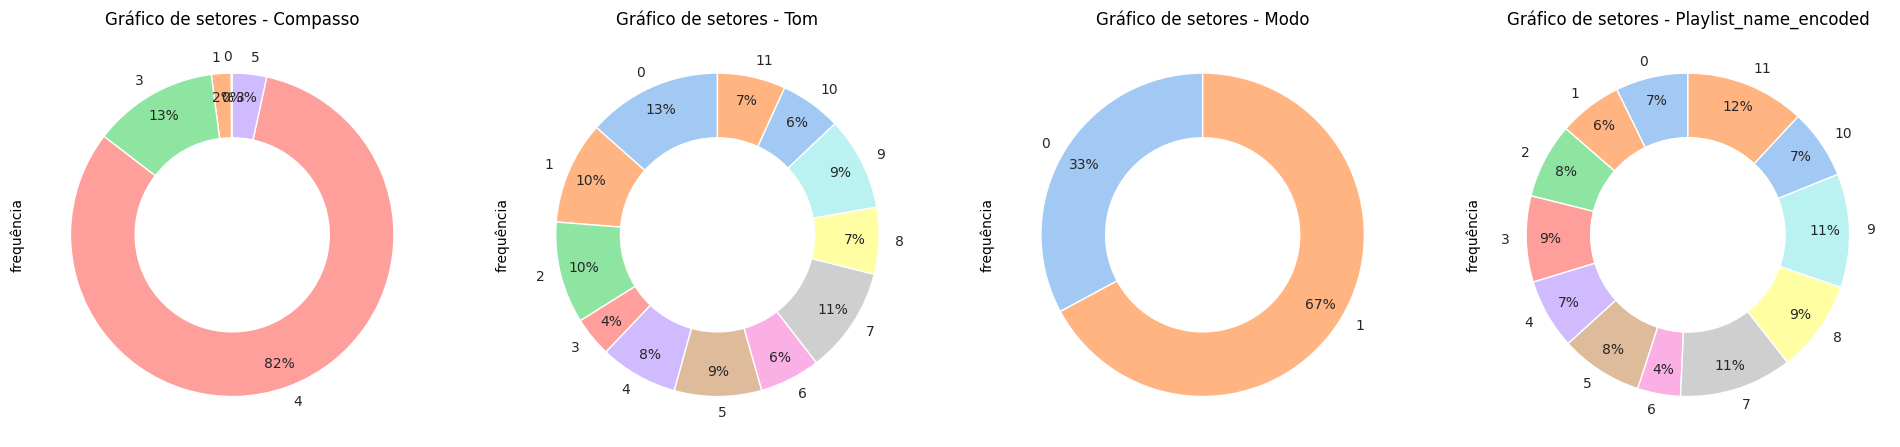

In [39]:
fig, ax = plt.subplots(nrows = 1, ncols = 4, figsize = (24, 6))

sector_plot(df_numeric, "Compasso", ax = ax[0])
sector_plot(df_numeric, "Tom", ax = ax[1])
sector_plot(df_numeric, "Modo", ax = ax[2])
sector_plot(df_numeric, "Playlist_name_encoded", ax = ax[3])

In [40]:
def histogram_plot(df, variable_name, ax1 = None, ax2 = None):
    if(ax1 is None and ax2 is None):
        fig, ax = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [1, 10]})
        ax1 = ax[0]
        ax2 = ax[1]
    # Boxplots
    sns.boxplot(x = df[variable_name], ax = ax1)
    # Histogramas
    sns.histplot(df[variable_name], kde = True, ax = ax2)

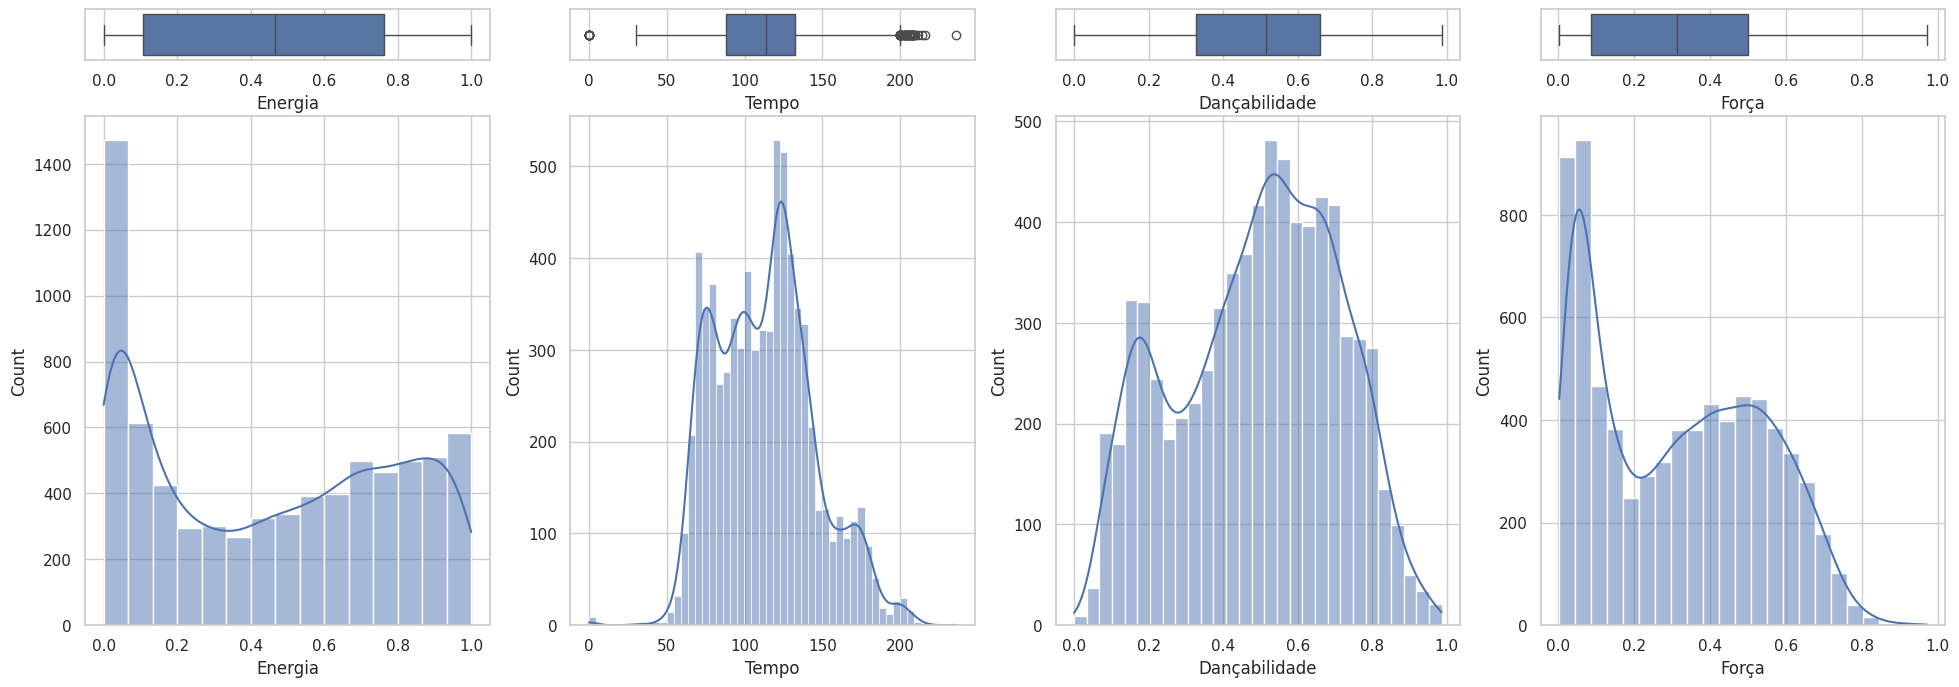

In [41]:
fig, ax = plt.subplots(2, 4, figsize=(24, 8), gridspec_kw={'height_ratios': [1, 10]})

histogram_plot(df_numeric, "Energia", ax1 = ax[0,0], ax2 = ax[1,0])
histogram_plot(df_numeric, "Tempo", ax1 = ax[0,1], ax2 = ax[1,1])
histogram_plot(df_numeric, "Dançabilidade", ax1 = ax[0,2], ax2 = ax[1,2])
histogram_plot(df_numeric, "Força", ax1 = ax[0,3], ax2 = ax[1,3])

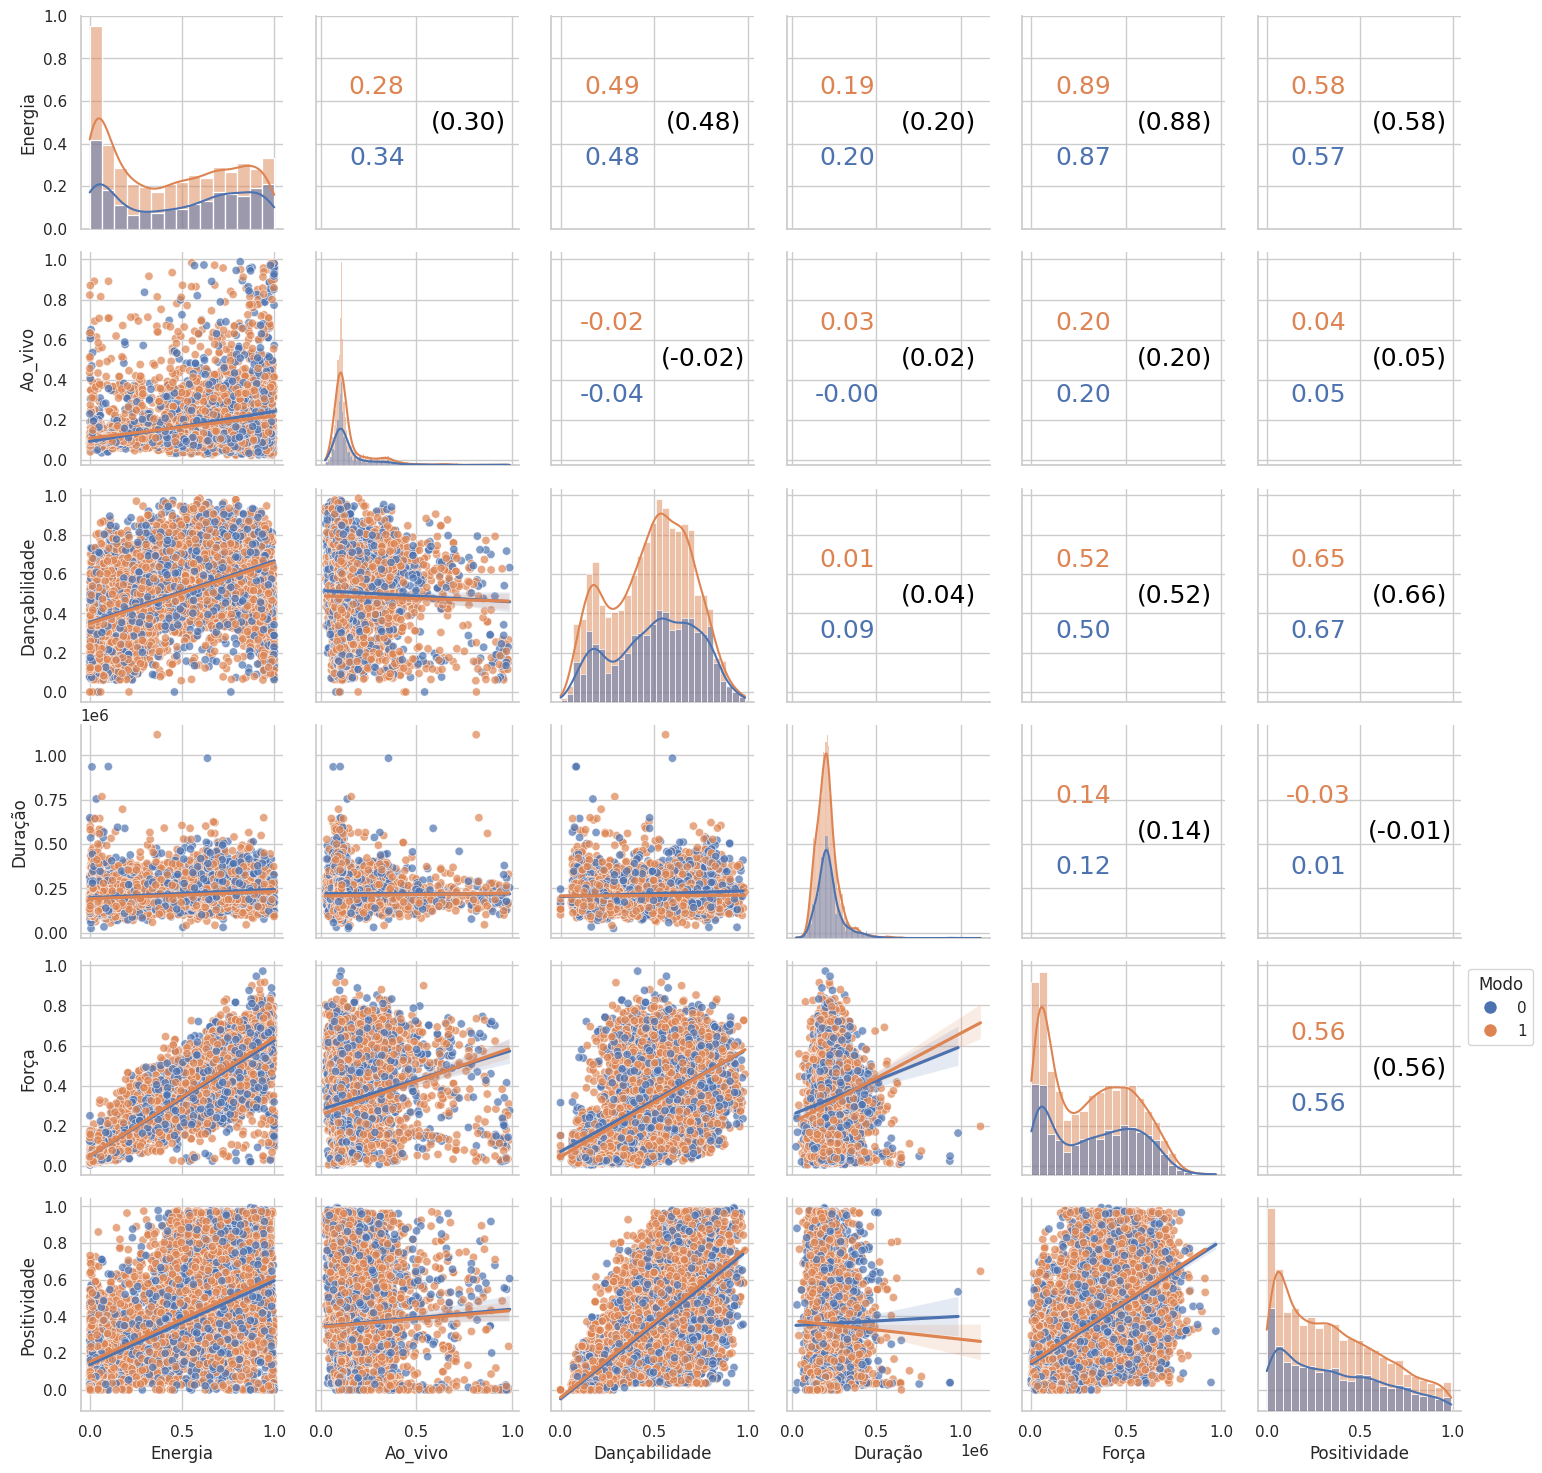

In [42]:
# Para não incluir uma variável Grupo, basta não fornecê-la para a função
# pair_plot(df, ['Energia', 'Ao_vivo', 'Dançabilidade', 'Duração', 'Força', 'Positividade'])
pair_plot(df, ['Energia', 'Ao_vivo', 'Dançabilidade', 'Duração', 'Força', 'Positividade'], hue = "Modo")

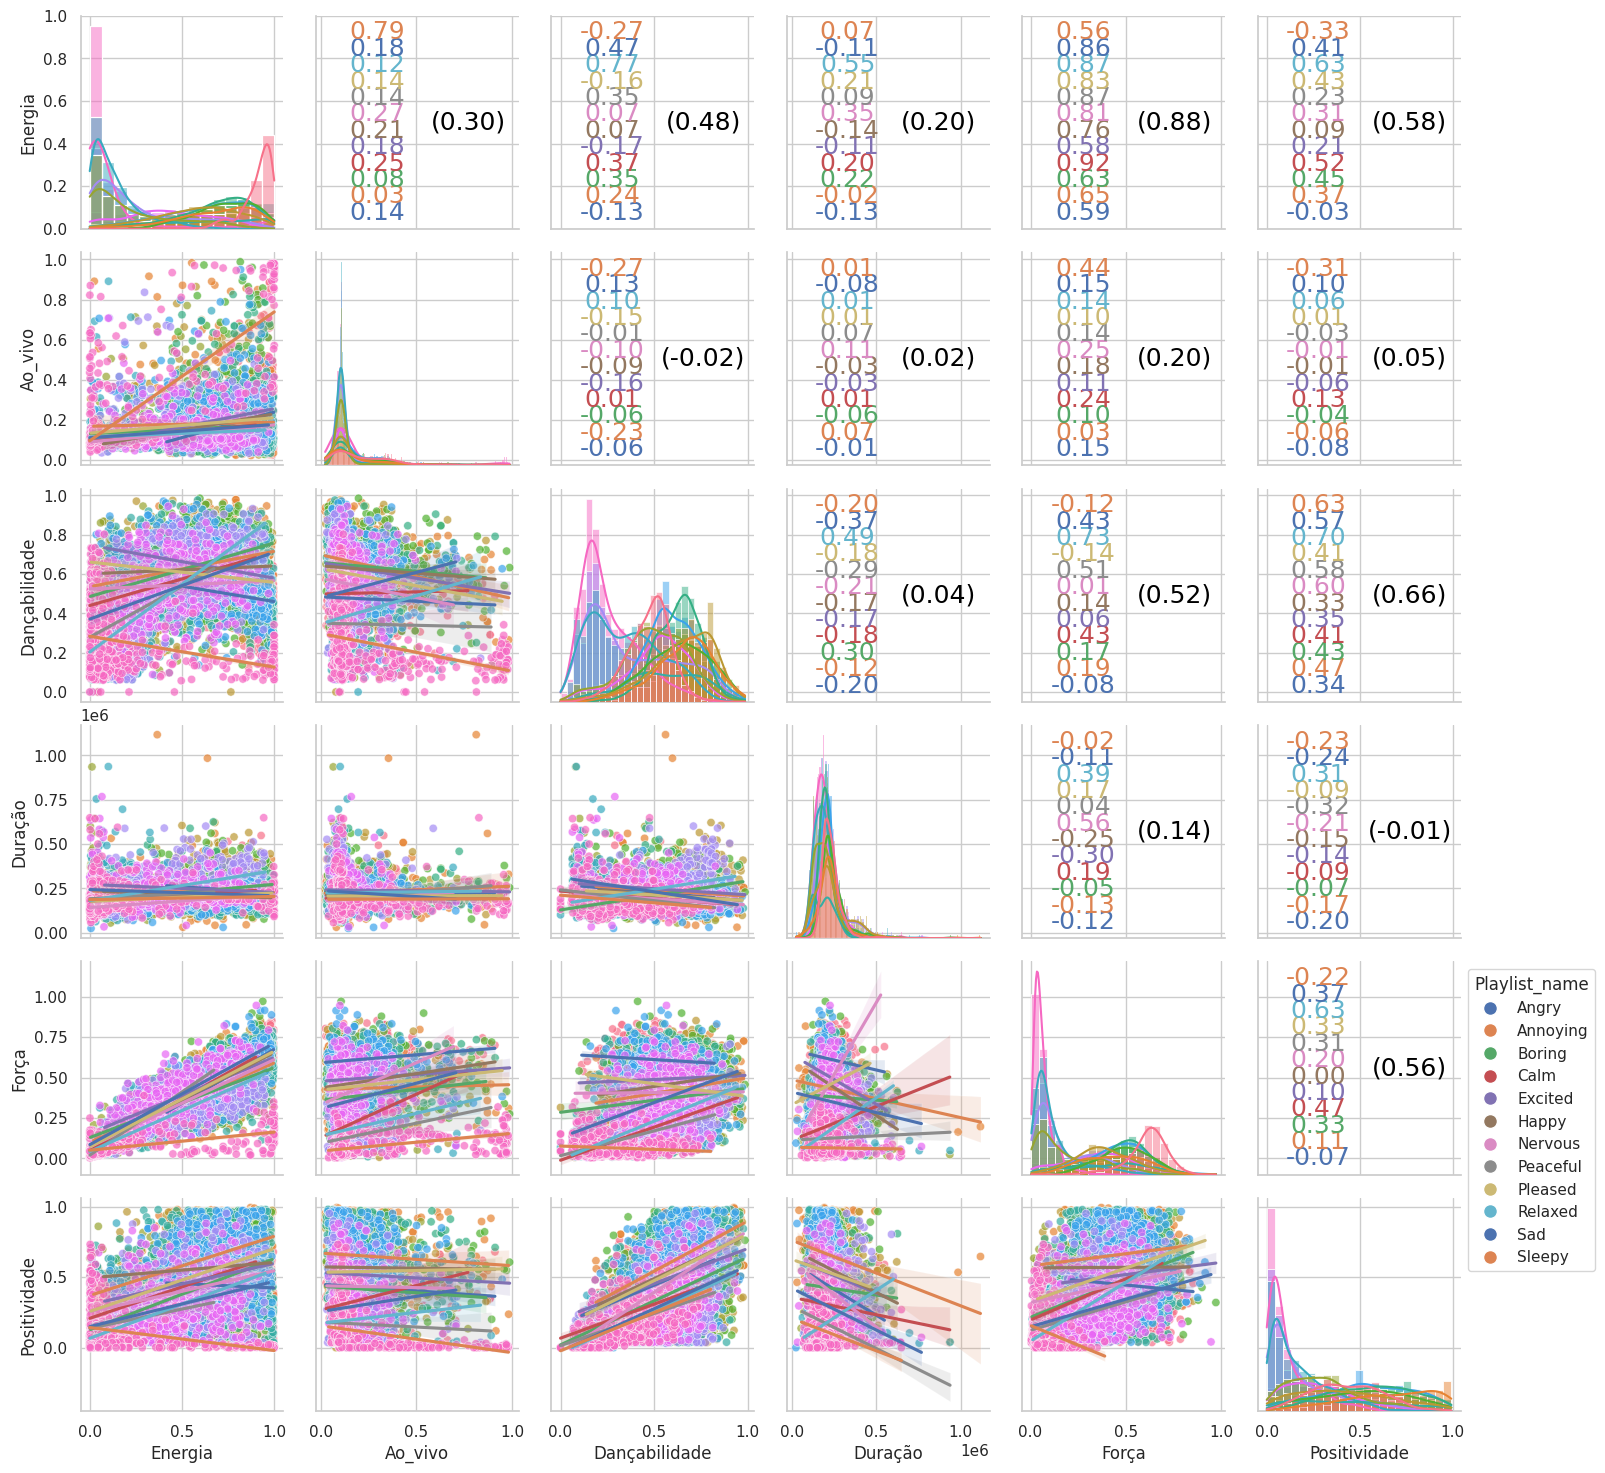

In [43]:
pair_plot(df, ['Energia', 'Ao_vivo', 'Dançabilidade', 'Duração', 'Força', 'Positividade'], hue = "Playlist_name")

<Figure size 640x480 with 0 Axes>

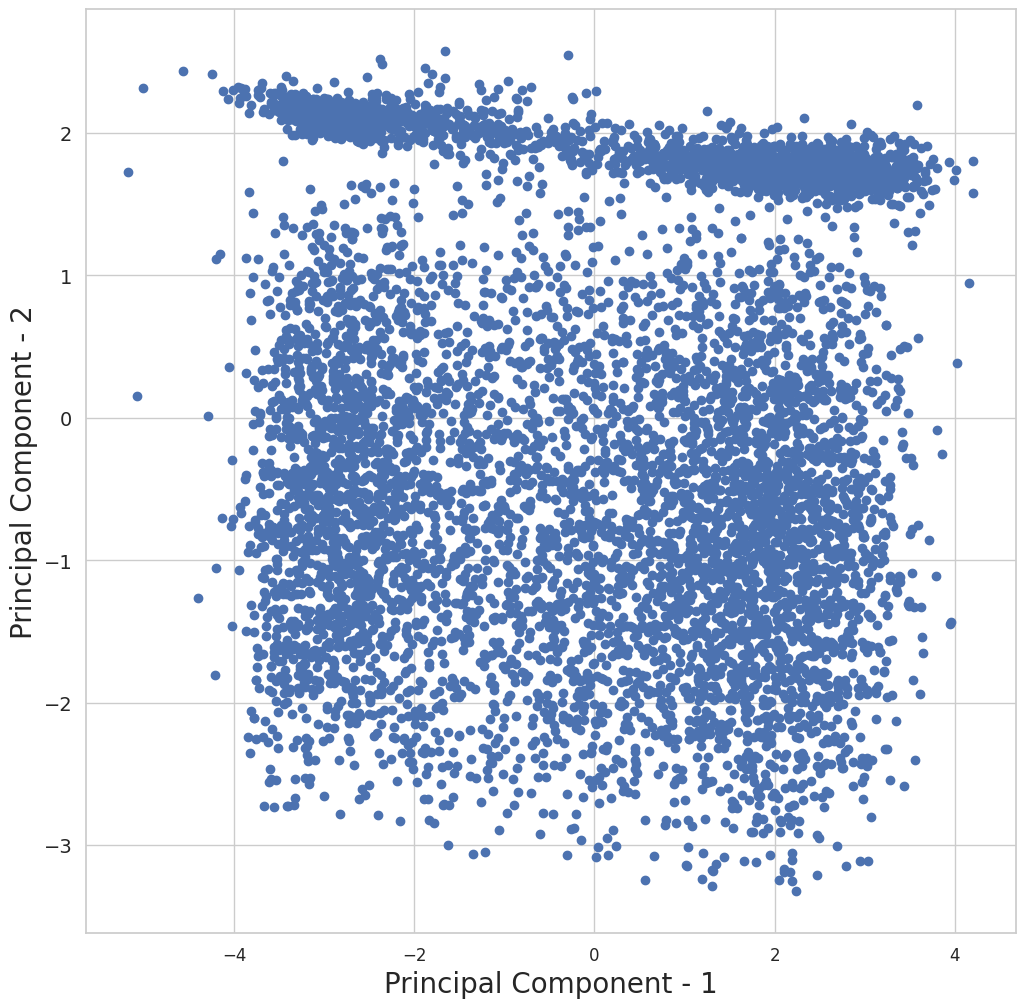

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
x = df_numeric.values
x = StandardScaler().fit_transform(x) # normalizing the features
feat_cols = ['feature'+str(i) for i in range(x.shape[1])]
normalised = pd.DataFrame(x,columns=feat_cols)
pca_df = PCA(n_components=2)
principalComponents_df = pca_df.fit_transform(x)
principalComponents_df = pd.DataFrame(data = principalComponents_df, columns = ['principal component 1', 'principal component 2'])

plt.figure()
plt.figure(figsize=(12,12))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Principal Component - 1',fontsize=20)
plt.ylabel('Principal Component - 2',fontsize=20)
plt.scatter(principalComponents_df['principal component 1'], principalComponents_df['principal component 2'])
